# DATA 3550: Applied Predictive Modeling
# Midterm Project: Vehicle Valuation for an Insurance Portfolio

**Middle Tennessee State University, Department of Mathematical Sciences**

Instructor: Dr. Ramchandra Rimal

Submission deadline: see the Canvas for the Midterm Project.

## Team and Contributions

Complete this table before submitting. Every member must submit the same final notebook
to the D2L dropbox, and every member must appear in this table with a specific,
verifiable description of what they did. "Helped with everything" is not a contribution
statement.

| Team member | Sections led | Specific contributions | Approx. share |
|---|---|---|---|
|Gloria Silva |2 - 4 |Fully completed the exploratory data analysis, splitting, and data quality |Did full 3 sections, and presentation slides on these 3 sections |
| | | | |
| | | | |
| | | | |

Team name:

Date completed:

## Use of AI Policy

Generative AI tools may be used to support tasks such as brainstorming ideas,
conceptualizing approaches, or debugging code. Their use does not alter your
fundamental responsibility for the integrity and quality of your academic work. You are
fully accountable for the accuracy, relevance, and originality of all submitted
material. Any information or content produced with AI assistance must be carefully
verified, as these tools can generate inaccurate, irrelevant, or fabricated information,
including false references. Your submissions must demonstrate critical thinking,
independent understanding, and meaningful engagement with the course material.

You must cite which tool you used, the purpose of use, and what content or ideas were
derived from it. Failure to verify, analyze, or appropriately attribute AI-assisted
content constitutes academic misconduct. If you are uncertain about acceptable use for
any part of this assignment, consult the instructor before submission.

**AI use declaration** (complete, or write "None"):

| Tool | What it was used for | Where it appears in this notebook |
|---|---|---|
| | | |

## The Scenario

You are on the analytics team at **Southern Cross Mutual**, a motor insurer. The
company holds a portfolio of 67,856 policies, and for each policy it records the market
value of the insured vehicle along with a small number of vehicle and policyholder
characteristics.

Two parts of the business need a vehicle valuation model.

**Underwriting** needs to sanity-check the vehicle value a customer declares when
applying for a policy. A declared value far from what the model expects is worth a
second look, either because it was mistyped or because it was overstated.

**Claims settlement** needs a defensible estimate of a vehicle's market value when a
vehicle is written off and the company must settle at market value. That estimate may
have to be explained to a customer who disagrees with it.

Your task is to build and compare regression models that predict vehicle value, and to
recommend one of them for deployment. Your manager is a senior claims professional with
no statistics background. Your final recommendation must make sense to her.

The company also wants to know **which characteristics matter most** for vehicle value,
and roughly how much each one is worth.

## Deliverables and Submission

**1. This notebook**, completed, named `Data3550MidPro_LastnameFirstInitial.ipynb`.
For example, `Data3550MidPro_RimalR.ipynb`.

- Submit the notebook file only. No data files, no folders, no zip archives.
- It is assumed you are working in a folder that contains a `Dataset` subfolder, so
  the data loads from `Dataset/AutoPortfolio.csv`. Do not change this path.
- Every code cell must run, in order, from a clean kernel. Before you submit, use
  **Kernel, then Restart Kernel and Run All Cells**, and confirm there are no errors.
  A notebook that does not run loses substantial credit regardless of its content.
- Once the team finalizes the notebook, distribute the same file to every member, and
  each member submits it individually.

**2. A PowerPoint presentation**, named `Data3550MidPro_GroupName.pptx`.
For example, `Data3550MidPro_LASSO.pptx` for a group named LASSO.

- 13 to 15 slides including the title slide.
- One member emails the presentation to the instructor.
- The presentation is graded against the separate presentation rubric.
- Structure the slides to follow Sections 2 through 11 of this notebook, in order.

## Formatting Requirements

Each section of this notebook must contain, in this order:

1. The section heading, already provided.
2. A short paragraph, in your own words, stating what you are about to do and why.
3. Your code, with comments explaining any step that is not obvious from the code itself.
4. A short paragraph interpreting what the output actually shows.

Write the interpretation for your manager, not for the grader. Precise, purposeful, and
concise. A number reported without units or without interpretation earns no credit.

## Grading

| Section | Task | Points |
|---|---|---|
| 2 | Exploratory data analysis | 12 |
| 3 | Splitting the data | 5 |
| 4 | Data quality: disguised missing values, structural zeros, rare categories | 12 |
| 5 | Feature engineering and encoding | 12 |
| 6 | Multiple linear regression | 12 |
| 7 | Ridge regression | 10 |
| 8 | Lasso regression | 10 |
| 9 | Elastic Net regression | 8 |
| 10 | Model comparison and residual diagnostics | 12 |
| 11 | Business recommendation | 7 |
| | **Notebook total** | **100** |
| | Presentation, graded separately against the rubric | 50 |

Points are lost for code that does not run, for results that are not explained, and for
claims that the output does not support.

## The Data

`Dataset/AutoPortfolio.csv` contains one row per policy. It is a real portfolio of
Australian motor insurance policies, published as the `dataCar` data set in the R
package `insuranceData` and used in De Jong and Heller (2008),
*Generalized Linear Models for Insurance Data*, Cambridge University Press.

### Data dictionary

| Column | Type | Meaning |
|---|---|---|
| `PolicyID` | identifier | Unique policy reference. Not a predictor. |
| `veh_value` | numeric | **Market value of the insured vehicle, in units of 10,000 Australian dollars.** A value of 1.06 means 10,600 dollars. This is the target. |
| `exposure` | numeric | Fraction of the policy year for which the policy was in force, between 0 and 1. |
| `clm` | binary | Whether the policy had at least one claim during the period. |
| `numclaims` | integer | Number of claims during the period. |
| `claimcst0` | numeric | Total claim cost in Australian dollars. Zero when there was no claim. |
| `veh_body` | categorical | Vehicle body type. 13 levels, listed below. |
| `veh_age` | ordinal | Vehicle age band, 1 (newest) to 4 (oldest). |
| `gender` | categorical | Policyholder gender, M or F. |
| `area` | categorical | Geographic rating area, A through F. |
| `agecat` | ordinal | Policyholder age band, 1 (youngest) to 6 (oldest). |
| `X_OBSTAT_` | text | An internal processing code carried over from the source system. |

Vehicle body codes: BUS, CONVT (convertible), COUPE, HBACK (hatchback), HDTOP (hardtop),
MCARA (motor caravan), MIBUS (minibus), PANVN (panel van), RDSTR (roadster),
SEDAN, STNWG (station wagon), TRUCK, UTE (utility).

### Two warnings about this data

**Not every column belongs in your model.** Before using a column as a predictor, ask
whether it would be known at the moment you need the prediction, and whether it could
plausibly influence vehicle value. Section 5 asks you to justify your predictor set in
writing. Choosing a predictor because it is present in the file is not a justification.

**Not every value in this file is trustworthy.** Section 4 asks you to find the problems.
They will not be flagged for you as `NaN`.

## 1. Environment and Data Loading

Run the cell below first. It reports the versions of every library this project uses,
so that a version problem surfaces immediately rather than as a confusing error later.
If any import fails, resolve it before continuing.

In [1]:
# Core numerical and data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling
import sklearn
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Statsmodels is used for the p-values needed in Section 6
import statsmodels.api as sm

# Display settings
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_style("whitegrid")

# One seed, used everywhere in this notebook, so results are reproducible.
RANDOM_STATE = 42

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("seaborn     ", sns.__version__)
print("scikit-learn", sklearn.__version__)

numpy        2.1.3
pandas       2.2.3
matplotlib   3.10.0
seaborn      0.13.2
scikit-learn 1.8.0


In [2]:
# Load the portfolio. Do not change this path.
autos = pd.read_csv("Dataset/AutoPortfolio.csv")

print("Rows:", autos.shape[0], " Columns:", autos.shape[1])
autos.head()

Rows: 67856  Columns: 12


,PolicyID,veh_value,exposure,clm,numclaims,claimcst0,veh_body,veh_age,gender,area,agecat,X_OBSTAT_
0,AU000001,1.06,0.303901,0,0,0.0,HBACK,3,F,C,2,01101 0 0 0
1,AU000002,1.03,0.648871,0,0,0.0,HBACK,2,F,A,4,01101 0 0 0
2,AU000003,3.26,0.569473,0,0,0.0,UTE,2,F,E,2,01101 0 0 0
3,AU000004,4.14,0.317591,0,0,0.0,STNWG,2,F,D,2,01101 0 0 0
4,AU000005,0.72,0.648871,0,0,0.0,HBACK,4,F,C,2,01101 0 0 0


### A note on sample size and runtime

The full portfolio has 67,856 policies. Cross-validated model tuning on all of them is
slow enough to be frustrating in a classroom setting, and it does not change any
conclusion you will reach.

Work with the random sample of 15,000 policies created below. Use `autos_sample`
everywhere from Section 2 onward. The seed is fixed, so every team gets the same sample
and your results will be comparable to each other and to the grading key.

In [3]:
autos_sample = autos.sample(n=15000, random_state=RANDOM_STATE).reset_index(drop=True)
print("Working sample:", autos_sample.shape)

Working sample: (15000, 12)


## 2. Exploratory Data Analysis (12 points)

Understand the portfolio before you model it. Everything you find here should inform a
decision you make later, so as you work, note which later section each finding affects.

**Required:**

**(a)** Report the shape, the column data types, and summary statistics for the numeric
columns. Do not print the entire data frame; use `.head()`, `.describe()`, and `.info()`.

**(b)** Examine the distribution of the target, `veh_value`. Produce a histogram.
Report its skewness. State in one sentence what the shape implies for modeling.

**(c)** Apply a log transformation to the target and plot the result. Report the
skewness again. State which version you will model and why.

**(d)** Examine the relationship between the target and each categorical predictor.
Box plots by category are appropriate. Which categories appear to command higher values?

**(e)** Examine the relationship between the target and the two ordinal predictors,
`veh_age` and `agecat`. Is the relationship monotonic in each case?

**(f)** Produce a correlation matrix for the numeric columns. Comment on any pair that
is strongly correlated and say what that would mean for a regression model.

**Interpretation required:** close the section with a short paragraph naming the three
findings that will most affect your modeling decisions, and which later section each one
affects.

In [4]:
# Your code for Section 2 here. Add as many cells as you need.
autos_sample.head()

,PolicyID,veh_value,exposure,clm,numclaims,claimcst0,veh_body,veh_age,gender,area,agecat,X_OBSTAT_
0,AU030348,4.63,0.046543,0,0,0.0,STNWG,1,F,C,4,01101 0 0 0
1,AU044051,1.09,0.473648,0,0,0.0,HBACK,3,F,A,5,01101 0 0 0
2,AU045164,1.64,0.013689,0,0,0.0,SEDAN,2,M,B,4,01101 0 0 0
3,AU013364,0.84,0.856947,0,0,0.0,HBACK,4,M,A,2,01101 0 0 0
4,AU008876,0.82,0.895277,0,0,0.0,HBACK,4,F,A,2,01101 0 0 0


In [5]:
autos_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   PolicyID   15000 non-null  object 
 1   veh_value  15000 non-null  float64
 2   exposure   15000 non-null  float64
 3   clm        15000 non-null  int64  
 4   numclaims  15000 non-null  int64  
 5   claimcst0  15000 non-null  float64
 6   veh_body   15000 non-null  object 
 7   veh_age    15000 non-null  int64  
 8   gender     15000 non-null  object 
 9   area       15000 non-null  object 
 10  agecat     15000 non-null  int64  
 11  X_OBSTAT_  15000 non-null  object 
dtypes: float64(3), int64(4), object(5)
memory usage: 1.4+ MB


#### Part (a):

In [6]:
# Here I will look at the shape of the data set
autos_sample.shape

(15000, 12)

12 columns: 1 will be our target variable (veh_value), and the other 11 are possible predictor variables.

1500 rows: This shows that I have a row-to-column ratio, so our models will have a lot of data to work with!

Column data types-

• Policy ID: Identifier

• Vehicle Value: numerical

• Exposure: numerical

• Claim: binary (0/1)

• Number of Claims: integer

• Claim Cost: numerical

• Vehicle Body: categorical

• Vehicle Age: ordinal

• Gender: categorical (binary, M/F)

• Area: categorical (A - F)

• AgeCat (policyholder age band): ordinal (1 - 6)

• X OBSTAT: internal processing code (potential drop)

In [7]:
autos_sample.describe()

,veh_value,exposure,clm,numclaims,claimcst0,veh_age,agecat
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,1.786948,0.470441,0.066467,0.070667,128.655822,2.668467,3.495933
std,1.227282,0.291125,0.249104,0.273151,1032.571723,1.064438,1.425290
min,0.000000,0.002738,0.000000,0.000000,0.000000,1.000000,1.000000
25%,1.020000,0.216290,0.000000,0.000000,0.000000,2.000000,2.000000
50%,1.500000,0.449008,0.000000,0.000000,0.000000,3.000000,3.000000
75%,2.190000,0.709103,0.000000,0.000000,0.000000,4.000000,5.000000
max,34.560000,0.999316,1.000000,3.000000,55922.129883,4.000000,6.000000


• STD: exposure, claim and number of claims all have a low standard deviation, meaning that most of the values are very close to the average. Claim Cost has a standard deviation of 1032. Even after looking at the min, max, and the mean we cab deduce that this is a very high standard deviation, which means that there is a huge amount of variety. Moving forward, the next step would be to check for outliers, and afterwards we will likely need Feature Scaling, specifically for our Ridge and Lasso Regression models in Sections 7, 8, and 9, and to be safe we will consider using that for Section 6 as well.

• Max: Some potential outliers we can already see is for the Vehicle Value and the Claim Cost.

#### Part (b):

<Axes: >

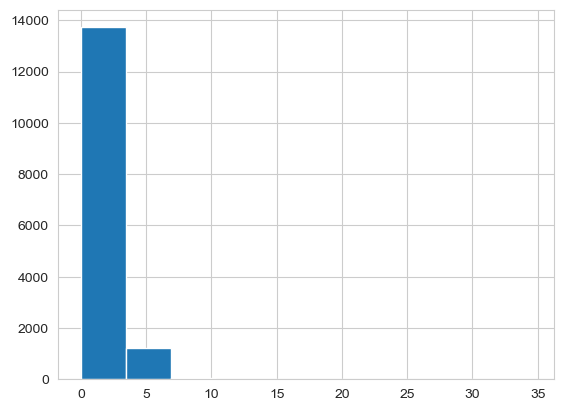

In [8]:
autos_sample['veh_value'].hist()

• Skeweness: This is a severely right skewed graph

• What this means for our future modeling work: We will not be able to plug this directly as is into our future models, we will have to remove outliers and apply a log transformation to spread out the rows and bring the further values closer together.

• This affects Sections 2, and 5-9. Section 5 we will remove the outliers, but in the next part (b) we will apply the log transformation. This will help ensure that our models in Sections 6-9 will be able to predict more accurately since we will have dealt with the skeweness.

#### Part (c):

In [9]:
# Applying the log transformation to the target variable
autos_sample['log_veh_value'] = np.log1p(autos_sample['veh_value'])

autos_sample[['veh_value', 'log_veh_value']].head()

,veh_value,log_veh_value
0,4.63,1.728109
1,1.09,0.737164
2,1.64,0.970779
3,0.84,0.609766
4,0.82,0.598837


Interpreting the results: 

• The gap has gotten smaller, from the original being over 5 times larger to now only 3 times larger.

• The orders are still from largest to smallest.

• The skeweness has resolved.

What this means for our future models:

• Now that we can safely build our models, we will have to remember that the the target variable is in log form. So when we are interpreting the final results, they will be in log form. So we will have to transform the results back to the original scale before testing our final error metrics. This affects Section 10.

<Axes: >

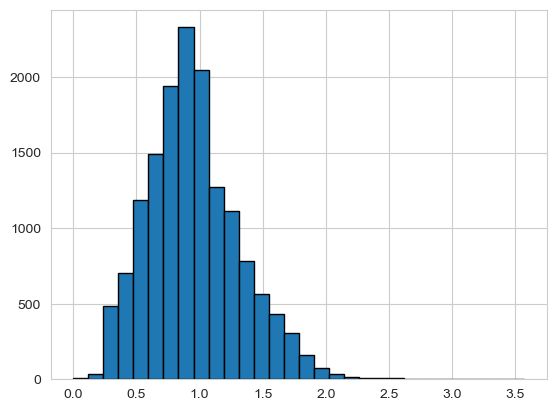

In [10]:
# Using a histogram to get a clearer picture of our log transformation
autos_sample['log_veh_value'].hist(bins=30, edgecolor='black')

We can see that the skeweness has been resolved.

#### Part (d):

<Axes: title={'center': 'log_veh_value'}, xlabel='veh_body'>

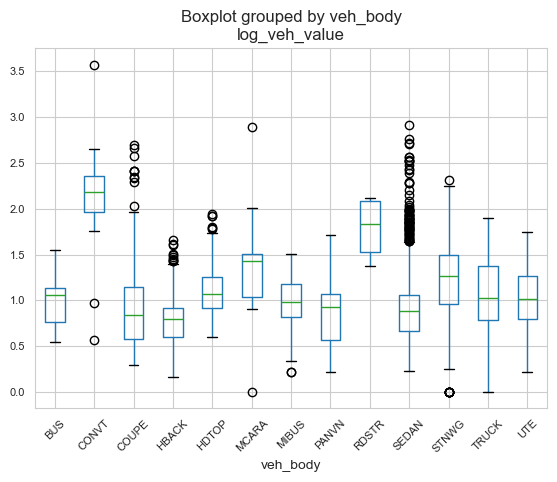

In [11]:
# Comparing the relationship between the vehicle value and vehicle body, which we will most likely use as a predictor variable
autos_sample.boxplot(column='log_veh_value', by='veh_body', fontsize=8, rot=45) #I made the font size smaller and rotated the horizontal axis labels because otheriwse it was too crowded and I couldn't read them

Interpreting the Results:

• The Median Lines: They are all at different points, so our models will have predictive power!

• The Boxes: Most of the boxes are sizeable, so there is some high variability in our data set. However, specifically for HBACK and HDTOP the boxes are smaller, so the values are more predictable.

• Overlap?: There is no overlap, so our models will have an easier time predicting!

• Individual Plot Points: We have lots of clear outliers here, specifically for CONVT, COUPE, HBACK, HDTOP, MCARA, MBUS, STNWG, with SEDAN being the one with the most outliers. We will have to deal with this most likely in Section 5.

<Axes: title={'center': 'log_veh_value'}, xlabel='gender'>

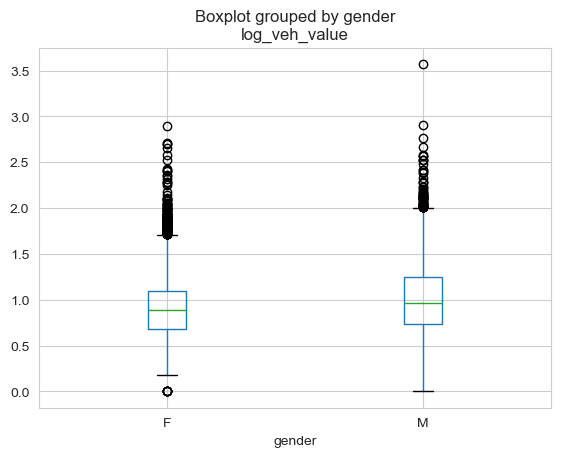

In [12]:
# Comparing the vehicle value with area, which we will most likely not use as this doesn't relate to vehicle value but rather would be geared more so towards policyholder
autos_sample.boxplot(column='log_veh_value', by='gender')

Interpreting the Results:

• The Median Lines: They are slightly at different points.

• The Boxes: The boxes are small/medium sized, so some predictive power.

• Overlap?: There is no overlap.

• Individual Plot Points: We have a severe case of outliers here.

<Axes: title={'center': 'log_veh_value'}, xlabel='area'>

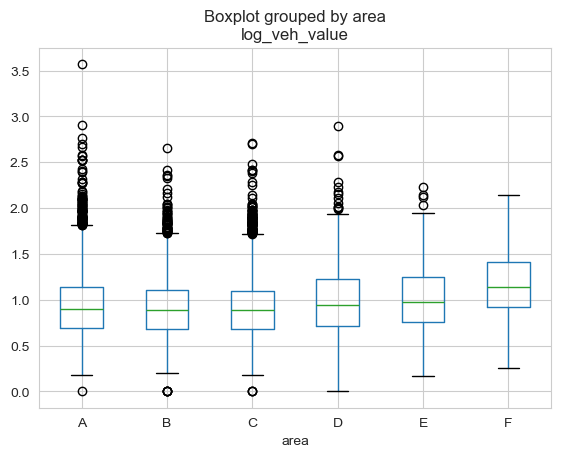

In [13]:
# Comparing vehicle value with area, which we may use as area coincides with insurance risk
autos_sample.boxplot(column='log_veh_value', by='area')

Interpreting the Results:

• The Median Lines: They are mostly at the same point within their boxes, so this means this doesn't hold a lot of predictive power.

• The Boxes: The boxes are smaller.

• Overlap?: There is no overlap.

• Individual Plot Points: We have a lot of outliers, specifically for areas A-E, A having the most and E having the least. It is worth wondering why!

#### Part (e):

In [14]:
# Looking at the relationship between vehicle value and vehicle age
autos_sample.groupby('veh_age')['log_veh_value'].median()

veh_age
1    1.195435
2    1.036737
3    0.854415
4    0.587787
Name: log_veh_value, dtype: float64

Interpreting the Results:

Yes, the relationship is monotonic as the the values consistently goes down from 1-4.

In [15]:
# Looking at the relationship between vehicle value and policyholder age band
autos_sample.groupby('agecat')['log_veh_value'].median()

agecat
1    0.920283
2    0.920283
3    0.936093
4    0.904218
5    0.935701
6    0.845868
Name: log_veh_value, dtype: float64

Interpreting the Results:

No, the relationship is not monotonic.

#### Part (f):

In [16]:
# Making a correlation matrix between the 3 numeric columns and seeing if there's any correlation.
autos_sample[['log_veh_value', 'exposure', 'claimcst0']].corr()

,log_veh_value,exposure,claimcst0
log_veh_value,1.000000,-0.001634,0.017954
exposure,-0.001634,1.000000,0.038575
claimcst0,0.017954,0.038575,1.000000


Interpreting the Results:

• We have very low correlation. For a Multiple Linear Regression model (Section 6), we will have to use more than 3 variables together otherwise the model will struggle. However, our Lasso and Elastic Net models (Sections 8 and 9) will be able to handle this fine since they can automatically shrink the coefficients to zero if they are not helping.

*Your interpretation of Section 2 goes here.*

For this Section, our 3 main findings were thar we have to be very careful about removing the outliers, transforming our results from our models from log back to original scale so that we can accurately report our findings, and that we have low correlation between our numeric categories, so we will have to be careful when choosing our predictor variables for certain models. This affects Sections 4 (outliers), 6 - 9 (predictor variables for the models), and 10 (original scale transformation).

## 3. Splitting the Data (5 points)

This section comes before any cleaning, imputation, encoding, or scaling. That ordering
is deliberate and it is graded.

**Required:**

**(a)** Separate the target from the predictors. Split into training and test sets with
80 percent for training, using `random_state=RANDOM_STATE`.

**(b)** Report the size of each set.

**(c)** In two or three sentences, explain why the split happens here rather than after
the data preparation sections that follow. Name the specific quantities that would be
contaminated if you did it the other way around.

**A rule that applies for the rest of this notebook:** every quantity you estimate from
data, a median, a mean, a standard deviation, a set of category levels, a threshold, is
computed on the training set only and then applied to the test set. If you find yourself
calling `.fit()` or `.fit_transform()` on test data, you have made an error.

#### Part (a):

In [18]:
# Your code for Section 3 here.
# Separating the target from the predictors.
X = autos_sample.drop(columns=['log_veh_value']) # The rest of the predictor variables remain
y = autos_sample['log_veh_value'] # The target variable

In [19]:
# Splitting into training and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, # Test size is 20%, so training size is 80%
    random_state=RANDOM_STATE # Using random state
)

In [20]:
# Verifying our splits
print("Training predictors shape:", X_train.shape)
print("Testing predictors shape:", X_test.shape)

Training predictors shape: (12000, 12)
Testing predictors shape: (3000, 12)


#### Part (b):

In [21]:
# Looking at the shapes
print(f"Training predictors shape (X_train): {X_train.shape}")
print(f"Training target shape (y_train):     {y_train.shape}")
print(f"Testing predictors shape (X_test):   {X_test.shape}")
print(f"Testing target shape (y_test):       {y_test.shape}")

Training predictors shape (X_train): (12000, 12)
Training target shape (y_train):     (12000,)
Testing predictors shape (X_test):   (3000, 12)
Testing target shape (y_test):       (3000,)


#### Part (c):

Splitting the data before the data preparation steps ensures that we have no data leakage, that our test data doesn't influence the training our our models. The specific quantities that would be contaminated would be the mean and standard deviation. Lastly, removing the outliers from our training set so that we can build the model, and then testing it on the test set where it does still have those outliers really tests how well built our models actually are and how they handle the messy data.

*Your explanation for Section 3 goes here.* 

 We have split our data set into two parts, the training part (80%) and the test part (20%). We do this before any other data cleaning and preprocessing to ensure our data sets are non contaminated, and that our training set has no outliers and we can see how our models will work on a test set that does have outliers.

## 4. Data Quality (12 points)

This data set contains no `NaN` values. It does contain problems. Real data usually
arrives this way: the problems are encoded as ordinary-looking values, and finding them
is part of the job.

**Required:**

**(a) A column carrying no information.** One column takes the same value in every row.
Identify it, show the evidence, and remove it. Explain in one sentence why a constant
column is worthless to a regression model.

**(b) Disguised missing values.** Examine the minimum of `veh_value`. Some policies
record a vehicle value that is impossible. Report how many, and explain why these are
better understood as missing data than as genuine observations.

**(c) The mechanism.** For the rows you identified in (b), compare the distribution of
`veh_age` against the distribution of `veh_age` in the rest of the data. Are the two
distributions the same? Support your answer with a table or a plot, and if you can, a
chi-square test of independence.

Then classify the missingness as **missing completely at random**, **missing at random**,
or **missing not at random**, using the definitions from Lecture 2, and justify your
choice from the evidence you just produced.

**(d) The treatment.** The affected column is the target. Explain why that rules out
imputation, and state what you will do instead. Apply it.

**(e) Structural zeros, for contrast.** The column `claimcst0` is zero for a large share
of policies. Report that share. Explain why those zeros are **not** missing data, and
what they actually mean. Contrast this with what you found in (b): both are zeros in a
numeric column, and they require opposite treatments.

**(f) Rare categories.** Examine the frequency of each level of `veh_body`. Several
levels appear very rarely. Report the counts. Decide whether to keep them as they are,
group them together, or drop those rows, and justify the decision. State what would go
wrong if a rare level appeared in your test set but not in your training set.

#### Part (a):

In [22]:
# Your code for Section 4 here.
# Finding the column that takes the same value in every row
unique_counts = X_train.nunique()
print("Unique value counts per column:\n", unique_counts)

Unique value counts per column:
 PolicyID     12000
veh_value      683
exposure       376
clm              2
numclaims        4
claimcst0      601
veh_body        13
veh_age          4
gender           2
area             6
agecat           6
X_OBSTAT_        1
dtype: int64


Interpreting the Results:

The X_OBSTAT is the one column that takes the same value in every row.

In [23]:
# Dropping X_OBSTAT from both the train and test sets
X_train = X_train.drop(columns=['X_OBSTAT_'])
X_test = X_test.drop(columns=['X_OBSTAT_'])

Why is a constant column worthless to a regression model?:

Because it contains no variance, so it won't be very good at actually training the model to explain or predict changes or patterns

#### Part (b):

In [25]:
# Looking at the minimum value of vehicle value
print(X_train['veh_value'].describe())

count    12000.000000
mean         1.776998
std          1.226304
min          0.000000
25%          1.020000
50%          1.500000
75%          2.170000
max         34.560000
Name: veh_value, dtype: float64


In [26]:
# Looking at how many rows have the 0 with our new set here
veh_value_min = (y_train == 0.0).sum() # Being mindful that vehicle value is our target variable and we used it for the Y and we had also applied the log transformation to it
print(f"Rows with 0: {veh_value_min}")

Rows with 0: 7


This is missing data because no vehicle actually has a value of 0. Even if it doesn't work at all, or is even completely destroyed, it still has at least some value to it due to the scrap metal, parts and other materials found in a vehicle.

#### Part (c):

In [27]:
# Comparing distribution of vehicle age against the distribution of vehicle age in the rest of the data
# First, I will show this with a table
missing = (y_train == 0.0)
ct = pd.crosstab(X_train['veh_age'], missing, normalize='columns') * 100
print("Percentage Distributions:\n", ct)

Percentage Distributions:
 log_veh_value      False  True 
veh_age                        
1              17.827066    0.0
2              24.764446    0.0
3              29.734012    0.0
4              27.674477  100.0


What this Means:
Our valid data is evenly distributed among all four categories, however all of our missing data is in category 4. So the two distributions are not the same.

In [28]:
# This shows the exact number of rows that are missing, instead of the percentages.
pd.crosstab(X_train['veh_age'], y_train == 0.0)

log_veh_value,False,True
veh_age,,
1,2138,0
2,2970,0
3,3566,0
4,3319,7


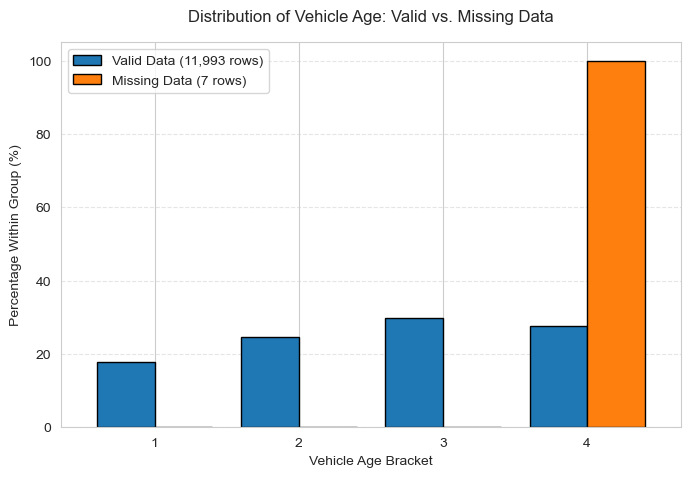

In [29]:
# I will also show the comparision of the two distributions with a plot
ct_pct = pd.crosstab(X_train['veh_age'], missing, normalize='columns') * 100

ct_pct.columns = ['Valid Data (11,993 rows)', 'Missing Data (7 rows)']

ct_pct.plot(kind='bar', figsize=(8, 5), width=0.8, edgecolor='black')

plt.title("Distribution of Vehicle Age: Valid vs. Missing Data", fontsize=12, pad=15)
plt.xlabel("Vehicle Age Bracket", fontsize=10)
plt.ylabel("Percentage Within Group (%)", fontsize=10)
plt.xticks(rotation=0) 
plt.grid(axis='y', linestyle='--', alpha=0.5)  

plt.show()

We can see that the missing data is in group 4.

In [30]:
# The Chi-Square Test of Independence
ctable = pd.crosstab(X_train['veh_age'], missing)
table_analysis = sm.stats.Table(ctable)
test_results = table_analysis.test_nominal_association()

print(f"Chi-Square Statistic: {test_results.statistic:.4f}")
print(f"P-value:              {test_results.pvalue:.4f}")

Chi-Square Statistic: 12.6932
P-value:              0.0053


Interpreting the Results:

• Chi-Square Statistic: This shows a significant divergence from the missing data being of random chance. 

• P-value: Since our P-value is significantly less than 0.05 (it is 0.0053), we can safely say that our missing values are statistically dependent on how old the vehicle is. And since Group 4 is where we have all of our missing data, and Group 4 means that the vehicle age is the oldest, this makes sense.

#### Is the missing data 'missing completely at random', 'missing at random', or 'missing not at random'?
• The missing data is 'Missing at Random'! 

• It is not 'missing completely at random', because it is not random. Rather, it is only happening to Group 4.

• It is not 'missing not at random', because the blank information isn't actual, useful information that is purposefully there and can be used as part of our predictive models.

• It is 'missing at random', because while it is routinely only in Group 4, and it isn't useful, purposeful information, it is information that was ommitted due to it simply being an older vehicle, and the information is simply incomplete. 

#### Part (d):

• Why can't we use imputation?: Since the missing rows affect our target variable, filling them with an average, mean or a median, is guessing at what that information could be. This could harm the affectiveness of our model. 

• What treatment will we apply instead?: Rather, we are going to drop the rows to preserve the quality of the data.

In [31]:
# Applying the treatment to those 7 missing rows
# This identifies where the target variable is valid
valid_target_mask = (y_train != 0.0)

# This filters out our predictors and the target variable using the new variable we created above
X_train = X_train[valid_target_mask]
y_train = y_train[valid_target_mask]

# Showing the new results
print("New X_train shape:", X_train.shape)
print("New y_train shape:", y_train.shape)

New X_train shape: (11993, 11)
New y_train shape: (11993,)


#### Part (e):

In [32]:
# Reporting the share of the large share of policies that are zero.
# Counting how many rows have a claim cost of zero.
zero_claims = (X_train['claimcst0'] == 0).sum()

# Calculating the share
share_of_zeros = (zero_claims / len(X_train)) * 100

print(f"Number of rows with 0 claim cost: {zero_claims}")
print(f"Share of policies with 0 claim cost: {share_of_zeros:.2f}%")

Number of rows with 0 claim cost: 11191
Share of policies with 0 claim cost: 93.31%


Interpreting the Results:

• This is not missing data. What this means is that the policyholder did not file an insurance claim

• This contrasts with Part (b) because those zeros were missing data at random, meaning the information was simply not filled out. However, this data is missing not at random, and the zeros are actually giving us useful information that we can use.

• They require opposite treatments. For the missing data in Part (b), we had to drop them, otherwise they would've corrupted our data. However, for this part we will keep them as is since they are telling us important information that can be used.

#### Part (f):

In [33]:
# Looking at the rare levels in Vehicle Body
print(X_train['veh_body'].value_counts())

veh_body
SEDAN    3964
HBACK    3315
STNWG    2839
UTE       792
HDTOP     316
TRUCK     299
COUPE     149
PANVN     137
MIBUS     124
MCARA      29
CONVT      16
BUS         9
RDSTR       4
Name: count, dtype: int64


Decide whether to keep them as they are, group them together, or drop those rows, and justify the decision. State what would go wrong if a rare level appeared in your test set but not in your training set.

Interpreting the Results:

• The rare level counts are RDSTR, BUS, CONVT, and MCARA. These four categories combined make up less than 0.5% of our data set.

What will we do with them?

• If we keep them as is, and they appear in our test set but not in our training set, then our models could crash. We would likely get an error.

• If we drop the rows, then we lose out on data and predictor information.

• So we make the decision to group them into 'Other'. That way, we can still use this predictor information, but our models won't crash.

In [34]:
# Grouping the rare levels together
rare_levels = ['MCARA', 'CONVT', 'BUS', 'RDSTR']

X_train['veh_body'] = X_train['veh_body'].replace(rare_levels, 'Other')
X_test['veh_body'] = X_test['veh_body'].replace(rare_levels, 'Other')

print(X_train['veh_body'].value_counts())

veh_body
SEDAN    3964
HBACK    3315
STNWG    2839
UTE       792
HDTOP     316
TRUCK     299
COUPE     149
PANVN     137
MIBUS     124
Other      58
Name: count, dtype: int64


*Your interpretation of Section 4 goes here, including your explicit classification of
the missingness mechanism and your justification for it.*

• Neither of our two predictor variables are constant columns

• The missing data is all in Group 4 of vehicle age

• The missing data in Group 4 is classified as Missing at Random, because that information was not filled out due to those vehicles simply being too old. 

• The missing data in claim cost was not actually missing, they were all zeros. So rather, we would describe it as Missing Not at Random, because that "missing" data was actually telling us useful information, and that there were zeros because there were no insurance claims. 

## 5. Feature Engineering and Encoding (12 points)

**Required:**

**(a) Justify your predictor set.** List every column in the file and, for each, state
whether you will use it as a predictor and why. Two of the columns should give you pause:

- Would this information be available at the moment the prediction is needed? A claims
  adjuster valuing a written-off vehicle knows the vehicle's characteristics. Does she
  know how many claims the policy will go on to have?
- Could this variable plausibly influence a vehicle's market value at all, or is it an
  artifact of how the policy was administered?

Any column you exclude must be excluded for a stated reason. Excluding a column because
it "did not help" is not a reason unless you show the evidence.

**(b) Ordinal versus nominal.** Two predictors, `veh_age` and `agecat`, are already
integers on an ordered scale. Three others, `veh_body`, `gender`, and `area`, are
unordered categories. Explain the difference and state how you will encode each group.
Explain specifically what would be lost by one-hot encoding an ordinal variable.

**(c) Build the preprocessing pipeline.** Use `ColumnTransformer` to scale the numeric
and ordinal predictors and one-hot encode the nominal ones. Fit it on the training data
only.

Set `handle_unknown="ignore"` on the encoder and explain in one sentence what problem
that setting prevents.

**(d) Engineer at least one new feature.** Create at least one feature that is not in the
original file. An interaction between two existing predictors is a reasonable choice.
State what real-world relationship you are trying to capture, and later, in Section 10,
report whether it helped.

**(e)** Report how many predictor columns the pipeline produces after encoding.

In [ ]:
# Your code for Section 5 here.

*Your justification for Section 5 goes here, including the predictor table from (a).*

## 6. Multiple Linear Regression (12 points)

**Required:**

**(a) Fit an initial model** on the training data using all of your predictors. Report
the training and test performance using RMSE, MAE, and R-squared.

**(b) Backward elimination.** Using `statsmodels`, fit the model and examine the
p-values. Remove the predictor with the highest p-value above 0.05, refit, and repeat.

**Stop after at most eight rounds**, even if some p-values remain above 0.05, and say
where you stopped. Report only the initial model summary and the final model summary.
Do not paste every intermediate step; it makes the notebook unreadable.

**(c)** Report how many predictors were removed and what happened to test R-squared.

**(d) A question worth answering carefully.** Lecture 3 argued that statistical
significance and predictive usefulness are different things. Did backward elimination
improve your model's performance on the test set? If not, what did it accomplish, and is
that worth having?

**(e) Cross-validated performance.** Compute a 5-fold cross-validated RMSE on the
training data for your final model, so that this model can be compared fairly against the
tuned models in Sections 7 through 9.

**(f) Interpret two coefficients** in plain language, in the units of the original
problem. Remember that your target is on a log scale and your numeric predictors are
standardized, so a raw coefficient is not directly interpretable. Convert before you
interpret.

In [ ]:
# Your code for Section 6 here.

*Your interpretation of Section 6 goes here.*

## 7. Ridge Regression (10 points)

**Required:**

**(a)** Fit a Ridge regression using the same predictors as your initial Section 6 model.
Select the penalty strength by 5-fold cross-validation on the training data, using
`GridSearchCV` over a grid spaced logarithmically, such as
`np.logspace(-2, 3, 10)`.

**(b)** Report the selected alpha and the cross-validated score at that value.

**(c) Plot the tuning curve.** Plot cross-validated RMSE against alpha on a log x-axis,
and mark the selected value. `GridSearchCV` stores everything you need in
`cv_results_["mean_test_score"]`. Do not simply report the winning number; show the
shape of the curve and describe it.

**(d)** Check whether the selected alpha sits at the edge of your grid. If it does, your
grid was too narrow. Widen it and rerun. Explain why an edge selection is a warning sign.

**(e)** Report test RMSE, MAE, and R-squared.

**(f)** Report how many coefficients Ridge set to exactly zero, and explain why that
number is what it is.

In [ ]:
# Your code for Section 7 here.

*Your interpretation of Section 7 goes here.*

## 8. Lasso Regression (10 points)

**Required:**

**(a)** Fit a Lasso regression using the same predictors, selecting alpha by 5-fold
cross-validation on the training data.

**(b)** Report the selected alpha and plot the tuning curve, as in Section 7.

**(c)** Report test RMSE, MAE, and R-squared.

**(d) Which predictors survived?** List the predictors whose coefficients Lasso set to
exactly zero, and the predictors it kept. Compare that list against the predictors that
backward elimination removed in Section 6. Do the two methods agree? Where they disagree,
what would explain it?

**(e) Interpret a zero.** Pick one predictor that Lasso zeroed. State precisely what
that does and does not tell you about the relationship between that predictor and vehicle
value. Lecture 5 covered the three things a zeroed coefficient does not mean.

**(f)** Compare the number of predictors Lasso retained against the number your Section 6
model used, and compare their test performance. If the smaller model performs about as
well, what is the practical argument for preferring it?

In [ ]:
# Your code for Section 8 here.

*Your interpretation of Section 8 goes here.*

## 9. Elastic Net Regression (8 points)

**Required:**

**(a)** Fit an Elastic Net, tuning **both** `alpha` and `l1_ratio` by 5-fold
cross-validation on the training data. A grid such as
`l1_ratio` in `[0.2, 0.5, 0.8]` crossed with a logarithmic alpha grid is reasonable.

**(b)** Report both selected values. State what the selected `l1_ratio` tells you: is the
fitted model behaving more like Ridge, more like Lasso, or genuinely between the two?

**(c) A notation check.** Lecture 5 wrote the Elastic Net penalty with two separate
weights, lambda-1 and lambda-2. Scikit-learn uses `alpha` and `l1_ratio` instead. In one
or two sentences, state the correspondence, so it is clear you know these are the same
model written two ways.

**(d)** Report test RMSE, MAE, and R-squared, and the number of non-zero coefficients.

In [ ]:
# Your code for Section 9 here.

*Your interpretation of Section 9 goes here.*

## 10. Model Comparison and Residual Diagnostics (12 points)

**Required:**

**(a) One comparison table.** Build a single table with one row per model and columns for
test RMSE, test MAE, test R-squared, cross-validated RMSE, and the number of non-zero
coefficients. All four models, evaluated on the same test set, with the same metrics.

**(b) Residual diagnostics.** For each model, produce residual plots. At minimum:
residuals against fitted values, and a histogram or Q-Q plot of the residuals. You may
overlay models or use a grid of panels. Describe what you see. Is there curvature? Does
the spread change across the range of fitted values? Are the residuals roughly symmetric?

**(c) Actual against predicted.** Plot predicted vehicle value against actual vehicle
value for your best model, with a 45 degree reference line. Comment on where the model
is accurate and where it is not.

**(d) The question this section is really asking.** Look at your comparison table. You
will probably find that the four models perform very similarly, possibly identically to
three decimal places.

That is not a mistake, and it is not a failure of the assignment. Explain why it happens.
Your answer should refer to the relationship between the number of predictors and the
number of observations, and to what a penalty term can and cannot do.

**(e) Given that, what distinguishes the models?** If accuracy does not separate them,
something else must. Consider at least: the number of predictors each model needs, how
stable the coefficients are, and how easily each model could be explained to a customer
disputing a settlement. Support your answer with evidence from your own output.

**(f) Did feature engineering help?** Compare a model fitted with your engineered feature
from Section 5(d) against the same model without it. Report the difference. Compare that
difference against the difference between any two of your four models. Which mattered
more, the feature or the model choice?

In [ ]:
# Your code for Section 10 here.

*Your interpretation of Section 10 goes here.*

## 11. Business Recommendation (7 points)

Write this section for the senior claims professional described in the scenario. She is
intelligent and experienced and has no statistics background. She will act on what you
write.

**Required:**

**(a) Recommend one model** for deployment. State a decision rule before you state the
answer: what criteria did you weigh, and in what priority? If two models are close on
accuracy, say what broke the tie and why that tiebreaker matters for this application.

**(b) Report expected accuracy in units she can use.** Not R-squared. Convert your error
metric back to Australian dollars and state, in one sentence, how far off a typical
prediction is. Remember that your model was fitted on a log scale.

**(c) The five factors that matter most.** The company asked for this specifically.
Report them in plain language, ranked, with a sense of how much each is worth. Be careful:
if your predictors are standardized and your target is logged, a raw coefficient is not
an answer to this question until you convert it.

**(d) State the limits.** Name at least three things this model cannot do or should not
be used for. Consider: vehicles unlike anything in the portfolio, the difference between
association and causation, and what happens as the market moves away from the period the
data covers.

**(e) One sentence for the settlement letter.** If a customer disputes a valuation, what
single sentence would you put in the response explaining how the figure was produced?

In [ ]:
# Any final code for Section 11 here, for example the converted top-five factors.

*Your business recommendation goes here.*

## Submission Checklist

Confirm each of these before submitting. This is not graded directly, but every item on
it corresponds to something that is.

- [ ] The notebook runs end to end with **Kernel, then Restart Kernel and Run All Cells**, with no errors.
- [ ] The contributions table at the top is complete, with specific contributions per member.
- [ ] The AI use declaration is complete, or states "None".
- [ ] Every section has an opening paragraph and a closing interpretation.
- [ ] The train and test split happens in Section 3, before any cleaning or encoding.
- [ ] Nothing is fitted on test data anywhere in the notebook.
- [ ] `RANDOM_STATE` is used everywhere a random seed is needed.
- [ ] Every number reported in prose has units, or is explicitly unitless.
- [ ] Section 11 contains no statistical jargon.
- [ ] The file is named `Data3550MidPro_LastnameFirstInitial.ipynb`.
- [ ] The presentation is 13 to 15 slides and is named `Data3550MidPro_GroupName.pptx`.
- [ ] Every team member has submitted the same final notebook to D2L.

## Reference

De Jong, P. and Heller, G. Z. (2008). *Generalized Linear Models for Insurance Data*.
Cambridge University Press. Data distributed in the R package `insuranceData`.